# 02 · Backtest L2 su FI-2010 (esperimenti E1 ed E2)

**Domanda di ricerca.** Quanto cambia la valutazione di una strategia di market making passivo quando le esecuzioni stimate con regole L2 vengono confrontate con un replay order-level che considera la posizione nella coda? Qui si guarda il primo termine del confronto: le **regole L2**.

Con dati L2 non si sa se un proprio ordine è stato eseguito: si vedono solo i prezzi e i volumi aggregati. Bisogna quindi scegliere una regola che lo deduca. Per un ordine di **acquisto** al prezzo *p*:

| Regola | Condizione | Informazione richiesta | Vantaggio | Bias |
|---|---|---|---|---|
| `touch` (E1) | il miglior prezzo in acquisto (*bid*) è ≤ *p*: il livello sullo stesso lato raggiunge la quota | solo il best bid | massima semplicità | fortemente ottimista: scatta anche a mercato fermo; va letta come **limite superiore** |
| `price-through` (E2) | il best bid scende **sotto** *p*: il livello sullo stesso lato supera la quota | solo il best bid | più prudente di `touch` | il livello può svuotarsi per cancellazioni, senza scambi |
| `cross` | il miglior prezzo in vendita (*ask*) scende fino a *p*: il lato opposto attraversa la quota | best bid e best ask | convenzione diffusa basata sull'attraversamento | esegue solo dopo che il prezzo è già arrivato alla quota |

Per una vendita le condizioni sono simmetriche. Nessuna regola è "più realistica" in assoluto: `price-through` e `cross` partono da ipotesi diverse e non sono ordinate in ogni sequenza di book. I modelli del book mostrano che l'esecuzione dipende dalla **posizione in coda** (Cont, Stoikov e Talreja, 2010; Huang, Lehalle e Rosenbaum, 2015), che i dati L2 non contengono.

```text
per ogni snapshot e ogni quota attiva (acquisto al prezzo p):
    touch:          eseguita se best_bid <= p
    price-through:  eseguita se best_bid <  p
    cross:          eseguita se best_ask <= p
```

**Esempio.** Quota di acquisto a 100,00 inserita con bid 100,00 e ask 100,01. Snapshot successivo con bid 100,00 e ask 100,01 (mercato fermo): `touch` la esegue, le altre due no. Snapshot con bid 99,99 e ask 100,01: eseguono `touch` e `price-through`, non `cross`. Snapshot con bid 99,99 e ask 100,00: eseguono tutte e tre.

FI-2010 ha prezzi normalizzati: il P&L è in **unità normalizzate** e le commissioni non si applicano. I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")                      # sessioni di test, strategia selezionata
validation = R.load(ROOT, "validation")          # griglia di parametri sulle sessioni di validazione
ablation = R.load(ROOT, "ablation")              # test ripetuto senza filtro di volatilità
variants = R.load(ROOT, "variants")              # varianti esplorative
selected = R.load_json(ROOT, "selected_params")  # parametri scelti in validazione

from market_making_tesi.evaluation import order_fill_rate
fi = test[test.dataset == "fi2010"]
stats = R.model_table_grouped(test, "fi2010", "final_equity")
fill_rate = fi.assign(fr=order_fill_rate(fi)).groupby("model").fr.mean()
R.show_box("In breve", [
    f"Con `touch` la strategia ottiene in media {it(stats.loc['touch', 'media'], 4)} per titolo-giorno, positiva {R.nel(stats.loc['touch', 'quota_positive'], 0)} dei casi.",
    f"Con `price-through` il risultato è {it(stats.loc['price-through', 'media'], 4)} e con `cross` {it(stats.loc['cross', 'media'], 4)}.",
    "Cambiando solo la regola di esecuzione, la stessa strategia passa da positiva a negativa (unità normalizzate).",
])
if fill_rate["touch"] > 0.95:
    display(Markdown(f"> ⚠️ **Attenzione:** con `touch` è eseguito il {pct(fill_rate['touch'], 1)} delle quote. "
                     "Un fill rate vicino al 100% indica che la regola conta come eseguite quasi tutte le quote, "
                     "anche quando nessuno ha scambiato: il risultato è un limite superiore, non una stima."))

> **In breve**
>
> - Con `touch` la strategia ottiene in media 0,3715 per titolo-giorno, positiva nel 100% dei casi.
> - Con `price-through` il risultato è -0,0044 e con `cross` -0,0141.
> - Cambiando solo la regola di esecuzione, la stessa strategia passa da positiva a negativa (unità normalizzate).

> ⚠️ **Attenzione:** con `touch` è eseguito il 97,7% delle quote. Un fill rate vicino al 100% indica che la regola conta come eseguite quasi tutte le quote, anche quando nessuno ha scambiato: il risultato è un limite superiore, non una stima.

## 1. Scelta dei parametri (validazione)

Sui giorni 2 e 3 si provano 12 combinazioni (due finestre di volatilità, tre soglie, due durate massime degli ordini) e si sceglie quella con il P&L medio più alto con `price-through`, la regola prudente prevista dal piano. La griglia completa è mostrata come analisi di sensibilità; più scuro = migliore.

In [2]:
display(R.validation_grid(validation, "fi2010", "final_equity").style.format("{:.4f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"**Parametri scelti:** {R.params_text('fi2010', selected['fi2010']['params'])}."))

**Parametri scelti:** volatilità su una finestra di 100 osservazioni; si opera solo sotto il 90° percentile della volatilità di calibrazione; ogni quota resta nel book al massimo 200 osservazioni.

## 2. Risultati sulle sessioni di test

Test: **7 giornate × 5 titoli = 35 titolo-giorni**. I titolo-giorni non sono 35 giornate indipendenti.

**Intervalli di confidenza.** I titoli della stessa giornata non sono osservazioni indipendenti: l'intervallo principale ricampiona **giornate (o ore) intere** con tutti i loro titoli (bootstrap per sessione, seme fisso). Con poche sessioni indipendenti (5 giornate ITCH, 4 ore Hyperliquid) anche questo intervallo è un'approssimazione e può sottostimare l'incertezza.

,giornate indipendenti,titolo-sessioni,"P&L medio, unità normalizzate (IC 95% per giornata)",IC 95% per riga (confronto),titolo-sessioni positive,quote eseguite (fill rate),turnover medio
touch,7,35,"0,3715 (0,2641; 0,5022)","(0,2435; 0,5294)",100%,"97,7%",456
price-through,7,35,"-0,0044 (-0,0057; -0,0029)","(-0,0073; -0,0018)",20%,"69,3%","29,86"
cross,7,35,"-0,0141 (-0,0159; -0,0118)","(-0,0184; -0,0102)",0%,"49,1%","18,12"


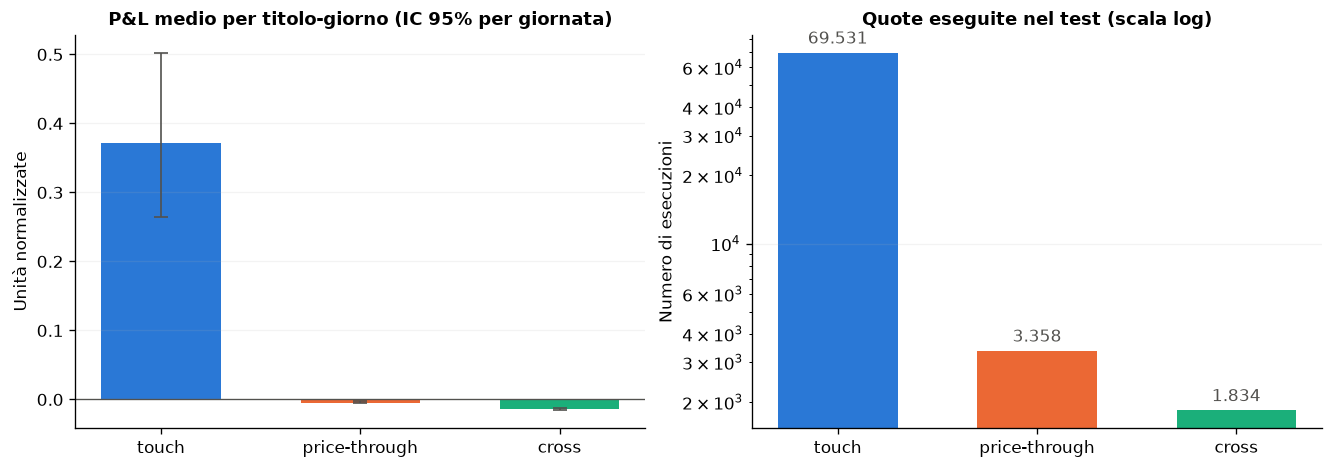

*Figura.* P&L medio per regola con intervallo di confidenza (sinistra) e numero di esecuzioni (destra). `touch` conta 38 volte le esecuzioni di `cross` ed è l'unica regola positiva. *Limite:* su FI-2010 non esiste un risultato "vero" con cui confrontare le regole: serve il replay della coda (notebook 04).

In [3]:
display(R.overview_table(test, "fi2010", "final_equity", 4).rename(
    columns={"P&L netto medio (IC 95% per sessione)": "P&L medio, unità normalizzate (IC 95% per giornata)"}))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
R.bar_by_model(axes[0], stats, "P&L medio per titolo-giorno (IC 95% per giornata)", "Unità normalizzate")
fills = fi.groupby("model").maker_fills.sum().reindex(["touch", "price-through", "cross"])
axes[1].bar([R.LABELS[m] for m in fills.index], fills, color=[R.COLORS[m] for m in fills.index], width=0.6)
for k, v in enumerate(fills):
    axes[1].text(k, v * 1.1, it(v), ha="center", color=R.INK)
axes[1].set(yscale="log", title="Quote eseguite nel test (scala log)", ylabel="Numero di esecuzioni")
axes[1].grid(axis="x", visible=False)
fig.savefig(FIGURES / "fi2010_test.png", dpi=180, bbox_inches="tight")
plt.show()
R.caption("P&L medio per regola con intervallo di confidenza (sinistra) e numero di esecuzioni (destra).",
          f"`touch` conta {it(fills['touch'] / fills['cross'])} volte le esecuzioni di `cross` ed è l'unica regola positiva.",
          "su FI-2010 non esiste un risultato \"vero\" con cui confrontare le regole: serve il replay della coda (notebook 04).")

## 3. Da dove viene il risultato

Ogni coppia di quote può chiudersi su **entrambi i lati** (si incassa lo spread), su **un solo lato** (si chiude a mercato pagando lo spread) o su **nessuno**. Il P&L si scompone in spread incassato rispetto al midpoint (*edge maker*), costo di liquidazione e movimento del prezzo sull'inventario.

In [4]:
display(R.fill_rates_table(R.fill_rates(test, "fi2010")))
display(R.decomposition_table(R.decomposition(test, "fi2010"), 4))
display(Markdown(
    "**Come leggerlo.** Con `cross` lo spread incassato è negativo: la regola esegue la quota quando il prezzo "
    "l'ha già raggiunta dal lato opposto, cioè a un prezzo peggiore del midpoint. Con `touch` quasi tutte le coppie "
    "si chiudono su entrambi i lati e lo spread viene incassato di continuo."))

,coppie quotate,entrambi i lati eseguiti,un solo lato eseguito,nessun lato eseguito,con fill parziale
touch,35.338,97%,3%,0%,0%
price-through,2.466,41%,53%,5%,0%
cross,1.958,17%,60%,23%,0%


,spread incassato (edge maker),costo di liquidazione,movimento del prezzo sull'inventario,= P&L lordo
touch,"0,3791","-0,0059","-0,0017","0,3715"
price-through,"0,0068","-0,0071","-0,0042","-0,0044"
cross,"-0,0074","-0,0060","-0,0007","-0,0141"


**Come leggerlo.** Con `cross` lo spread incassato è negativo: la regola esegue la quota quando il prezzo l'ha già raggiunta dal lato opposto, cioè a un prezzo peggiore del midpoint. Con `touch` quasi tutte le coppie si chiudono su entrambi i lati e lo spread viene incassato di continuo.

## 4. Il filtro di volatilità serve?

Le stesse sessioni di test sono ripetute con la strategia **sempre attiva**. Differenza positiva = il filtro migliora il risultato.

In [5]:
effect = R.filter_effect(test, ablation, "fi2010", "final_equity")
display(R.filter_table(effect, 4))
pt = effect.loc["price-through"]
verdict = ("migliora" if pt["IC95 basso"] > 0 else "peggiora" if pt["IC95 alto"] < 0 else "non cambia in modo significativo")
display(Markdown(f"**Come leggerlo.** Con `price-through` il filtro {verdict} il risultato "
                 f"(differenza {it(pt['differenza'], 4)} unità normalizzate)."))

,con filtro,sempre attiva,differenza (IC 95%),sessioni migliori con filtro,tempo in cui opera
modello,,,,,
touch,"0,3715","0,3535","0,0179 (-0,0061; 0,0383)",63%,85%
price-through,"-0,0044","-0,0026","-0,0019 (-0,0031; -0,0006)",23%,85%
cross,"-0,0141","-0,0141","0,0000 (-0,0016; 0,0019)",46%,85%


**Come leggerlo.** Con `price-through` il filtro peggiora il risultato (differenza -0,0019 unità normalizzate).

In [6]:
R.show_box("Il profitto L2 è un risultato della strategia o dell'ipotesi di fill?", [
    "Le tre regole usano gli stessi dati, la stessa strategia e gli stessi parametri: le differenze dipendono solo dall'ipotesi di esecuzione.",
    f"Solo `touch`, con un fill rate del {pct(fill_rate['touch'], 1)}, produce un risultato positivo: è un limite superiore ottimistico.",
    "Su FI-2010 non si può stabilire quale regola sia corretta, perché manca la coda degli ordini: la risposta arriva dal replay order-level (notebook 04).",
])

> **Il profitto L2 è un risultato della strategia o dell'ipotesi di fill?**
>
> - Le tre regole usano gli stessi dati, la stessa strategia e gli stessi parametri: le differenze dipendono solo dall'ipotesi di esecuzione.
> - Solo `touch`, con un fill rate del 97,7%, produce un risultato positivo: è un limite superiore ottimistico.
> - Su FI-2010 non si può stabilire quale regola sia corretta, perché manca la coda degli ordini: la risposta arriva dal replay order-level (notebook 04).